# Non-Parametric Tests — Instructor Notebook

## 1. Lesson Title
**Non-Parametric Tests Using Python and `pingouin` / `scipy.stats`**

> This notebook contains the complete worked solutions. Use it for delivery and to mark student submissions.

## 2. Learning Outcomes

Students should be able to:
1. Explain what non-parametric tests are
2. Understand when to use non-parametric tests instead of parametric tests
3. Identify suitable tests for different research questions
4. Load and inspect datasets for practice
5. Run common non-parametric tests in Python
6. Interpret p-values and test results correctly
7. Perform post hoc comparisons when needed
8. Choose between parametric and non-parametric methods

## 3–6. Concept Recap

Non-parametric tests do not rely on strong assumptions (normality, equal variances). They typically operate on **ranks** rather than raw values, making them robust to skewness, outliers, and small samples.

| Research Situation | Parametric | Non-Parametric |
|---|---|---|
| 2 independent groups | Independent t-test | **Mann–Whitney U** |
| 2 related groups | Paired t-test | **Wilcoxon signed-rank** |
| 3+ independent groups | One-Way ANOVA | **Kruskal–Wallis** |
| 3+ related groups | RM ANOVA | **Friedman** |
| Correlation | Pearson | **Spearman** |

## 7. Install Required Libraries

In [1]:
# !pip install pingouin pandas numpy scipy seaborn matplotlib scikit-posthocs

## 8. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import scikit_posthocs as sp

# Part A — Mann–Whitney U Test

## 9. Scenario
Compare stress scores between Online vs Physical learners (skewed data).

## 10. Load the Dataset

In [3]:
df_mw = pd.read_csv('../../00-data/stress_score.csv', index_col=0)
df_mw.head()

,Group,Stress_Score
0,Online,20.12
1,Online,6.33
2,Online,15.25
3,Online,12.30
4,Online,12.64


## 11. Explore the Data

In [4]:
print(df_mw.groupby('Group')['Stress_Score'].agg(['mean', 'median', 'std', 'count']))

               mean  median        std  count
Group                                        
Online    22.022667  13.425  24.323671     30
Physical  24.711667  25.485   3.454648     30


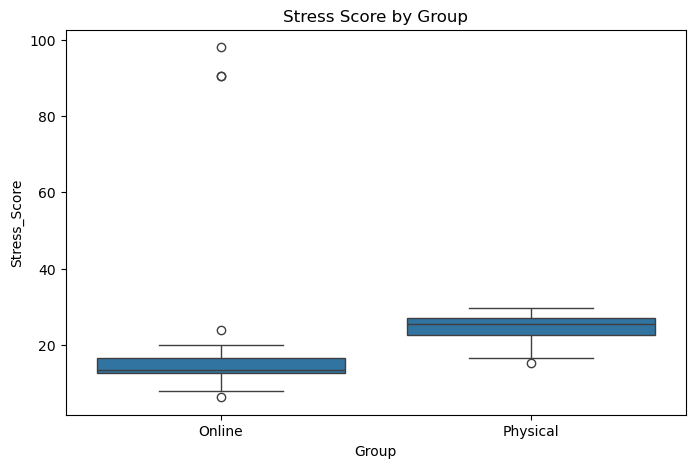

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_mw, x='Group', y='Stress_Score')
plt.title('Stress Score by Group')
plt.show()

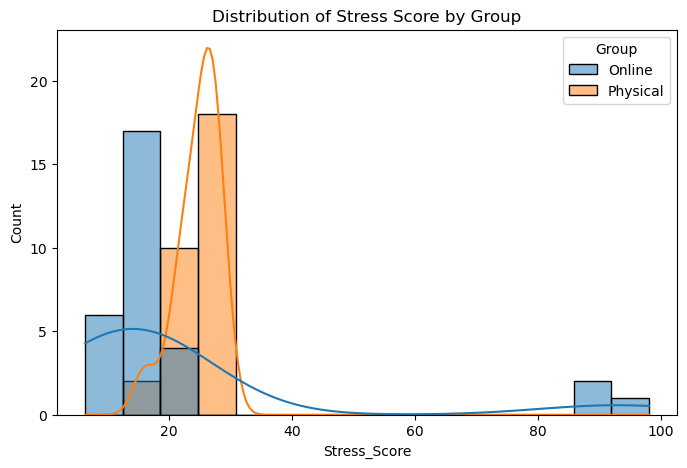

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_mw, x='Stress_Score', hue='Group', kde=True)
plt.title('Distribution of Stress Score by Group')
plt.show()

## 12. Check Normality

If either group is non-normal → Mann–Whitney U is justified.

In [7]:
for g in df_mw['Group'].unique():
    subset = df_mw[df_mw['Group'] == g]['Stress_Score']
    print(g)
    print(pg.normality(subset))
    print()

Online
                     W          pval  normal
Stress_Score  0.479353  3.263911e-09   False

Physical
                    W      pval  normal
Stress_Score  0.91481  0.019714   False



## 13. Run Mann–Whitney U Test

- H0: the two groups come from similar distributions
- H1: the two groups differ

In [8]:
online = df_mw[df_mw['Group'] == 'Online']['Stress_Score']
physical = df_mw[df_mw['Group'] == 'Physical']['Stress_Score']

mw_result = stats.mannwhitneyu(online, physical, alternative='two-sided')
print(mw_result)

MannwhitneyuResult(statistic=np.float64(112.0), pvalue=np.float64(6.045949421012785e-07))


### Now run the test we were told not to use

The claim is that a t-test is the wrong tool here. Do not take that on trust — run it.

In [9]:
# Standalone on purpose: this cell reloads and re-imports so it runs whether or
# not you have filled in the TODO cells above.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
df_mw = pd.read_csv('../../00-data/stress_score.csv', index_col=0)
online = df_mw[df_mw['Group'] == 'Online']['Stress_Score']
physical = df_mw[df_mw['Group'] == 'Physical']['Stress_Score']

t_stat, t_p = stats.ttest_ind(online, physical, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(online, physical, alternative='two-sided')

print(f"Welch t-test      t = {t_stat:7.3f}   p = {t_p:.4f}   {'SIGNIFICANT' if t_p < 0.05 else 'not significant'}")
print(f"Mann-Whitney U    U = {u_stat:7.1f}   p = {u_p:.6f}   {'SIGNIFICANT' if u_p < 0.05 else 'not significant'}")
print()
print(df_mw.groupby('Group')['Stress_Score'].agg(['mean', 'median', 'std']).round(2))
print("""
The two tests disagree, and the summary table shows why.

The Online group contains a few extreme scores. They drag its MEAN up to sit
near the Physical mean, and they inflate its standard deviation enormously.
The t-test compares means and divides by that inflated spread, so it sees a
small difference with a huge error bar and reports nothing.

Mann-Whitney never looks at the values, only at their order. Almost every
Online learner ranks below almost every Physical learner, which is exactly the
pattern the boxplot shows, and the rank test finds it immediately.

Compare the MEDIANS instead of the means and the difference is obvious.
""")

Welch t-test      t =  -0.599   p = 0.5533   not significant
Mann-Whitney U    U =   112.0   p = 0.000001   SIGNIFICANT

           mean  median    std
Group                         
Online    22.02   13.42  24.32
Physical  24.71   25.48   3.45

The two tests disagree, and the summary table shows why.

The Online group contains a few extreme scores. They drag its MEAN up to sit
near the Physical mean, and they inflate its standard deviation enormously.
The t-test compares means and divides by that inflated spread, so it sees a
small difference with a huge error bar and reports nothing.

Mann-Whitney never looks at the values, only at their order. Almost every
Online learner ranks below almost every Physical learner, which is exactly the
pattern the boxplot shows, and the rank test finds it immediately.

Compare the MEDIANS instead of the means and the difference is obvious.



## 14. Interpretation Template

> A Mann–Whitney U test was conducted to compare stress scores between online and physical learners. With these synthetic data the test statistic and p-value should be examined: if `p < 0.05`, conclude that the distributions of stress scores differ significantly between the two groups; otherwise, conclude there is no statistically significant difference.

# Part B — Wilcoxon Signed-Rank Test

## 15. Scenario
Same students measured before and after a confidence workshop (paired, non-normal).

## 16. Load the Paired Dataset

In [10]:
df_wil = pd.read_csv('../../00-data/confidence_workshop.csv')
df_wil.head()

,Student_ID,Confidence_Before,Confidence_After
0,1,54.5,27.8
1,2,62.6,69.6
2,3,39.5,41.8
3,4,63.8,36.4
4,5,51.7,55.7


## 17. Visualize Paired Data

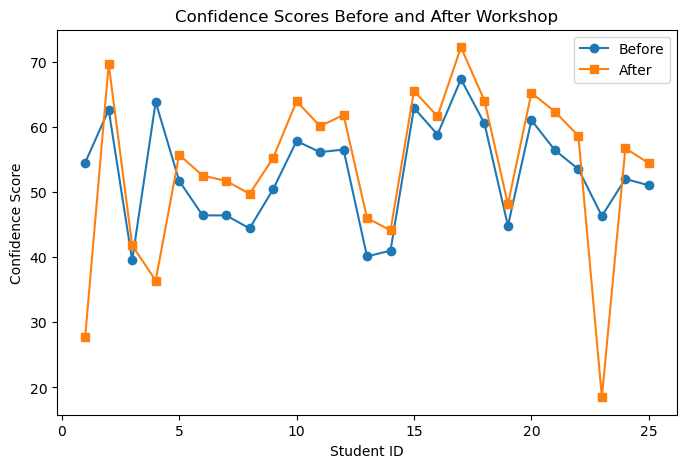

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(df_wil['Student_ID'], df_wil['Confidence_Before'], marker='o', label='Before')
plt.plot(df_wil['Student_ID'], df_wil['Confidence_After'], marker='s', label='After')
plt.title('Confidence Scores Before and After Workshop')
plt.xlabel('Student ID')
plt.ylabel('Confidence Score')
plt.legend()
plt.show()

## 18. Run Wilcoxon Signed-Rank Test

- H0: median paired difference is zero
- H1: median paired difference is not zero

In [12]:
wil_result = stats.wilcoxon(df_wil['Confidence_Before'], df_wil['Confidence_After'])
print(wil_result)

WilcoxonResult(statistic=np.float64(72.0), pvalue=np.float64(0.01487055165581049))


### Check the assumption first, then compare

Section 12 tested normality before the Mann-Whitney U. The original notebook never did
the equivalent check here — and for a paired test the thing that must be normal is the
**differences**, not the two columns. Check it, then run both tests.

In [13]:
# Standalone on purpose: this cell reloads and re-imports so it runs whether or
# not you have filled in the TODO cells above.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
df_wil = pd.read_csv('../../00-data/confidence_workshop.csv')
diff = df_wil['Confidence_After'] - df_wil['Confidence_Before']

sw = stats.shapiro(diff)
print(f"Shapiro-Wilk on the DIFFERENCES   W = {sw.statistic:.4f}   p = {sw.pvalue:.6f}")
print("differences are normal\n" if sw.pvalue > 0.05
      else "differences are NOT normal -> the paired t-test is not safe here\n")

t_res = stats.ttest_rel(df_wil['Confidence_After'], df_wil['Confidence_Before'])
w_res = stats.wilcoxon(df_wil['Confidence_After'], df_wil['Confidence_Before'])

print(f"Paired t-test     t = {t_res.statistic:7.3f}   p = {t_res.pvalue:.4f}   {'SIGNIFICANT' if t_res.pvalue < 0.05 else 'not significant'}")
print(f"Wilcoxon          W = {w_res.statistic:7.1f}   p = {w_res.pvalue:.6f}   {'SIGNIFICANT' if w_res.pvalue < 0.05 else 'not significant'}")
print()
print(f"students who improved: {(diff > 0).sum()} of {len(diff)}")
print(f"mean difference:   {diff.mean():+.2f}")
print(f"median difference: {diff.median():+.2f}")
print("""
The paired t-test says the workshop did nothing. Look at the counts: most
students improved. A small number collapsed, and because the t-test averages
the raw differences, those few large negative values cancel out everyone
else's gain and drag the mean to roughly zero.

Wilcoxon ranks the differences by size and counts how many go each way, so a
handful of large drops cannot outvote a large majority of consistent gains.

The median difference is the honest summary of what happened here.
""")

Shapiro-Wilk on the DIFFERENCES   W = 0.4959   p = 0.000000
differences are NOT normal -> the paired t-test is not safe here

Paired t-test     t =   0.333   p = 0.7419   not significant
Wilcoxon          W =    72.0   p = 0.014871   SIGNIFICANT

students who improved: 22 of 25
mean difference:   +0.71
median difference: +4.20

The paired t-test says the workshop did nothing. Look at the counts: most
students improved. A small number collapsed, and because the t-test averages
the raw differences, those few large negative values cancel out everyone
else's gain and drag the mean to roughly zero.

Wilcoxon ranks the differences by size and counts how many go each way, so a
handful of large drops cannot outvote a large majority of consistent gains.

The median difference is the honest summary of what happened here.



## 19. Interpretation Template

> A Wilcoxon signed-rank test was conducted to compare confidence scores before and after the workshop. Because the synthetic data was generated with an upward shift after the workshop, expect `p < 0.05` and conclude that there was a **statistically significant** increase in confidence scores following the workshop.

# Part C — Kruskal–Wallis Test

## 20. Scenario
Compare assignment scores across 3 revision styles (Notes / Videos / Mixed) with skewed data.

## 21. Load the Dataset

In [14]:
df_kw = pd.read_csv('../../00-data/assignment_score.csv', index_col=0)
df_kw.head()

,Revision_Style,Assignment_Score
0,Notes,143.28
1,Notes,146.86
2,Notes,181.57
3,Notes,8.40
4,Notes,16.35


## 22. Explore the Data

In [15]:
print(df_kw.groupby('Revision_Style')['Assignment_Score'].agg(['mean', 'median', 'std', 'count']))

                   mean  median        std  count
Revision_Style                                   
Mixed           36.5564   32.54  15.215637     25
Notes           28.5396   12.49  49.357864     25
Videos          20.9032   17.49  14.018018     25


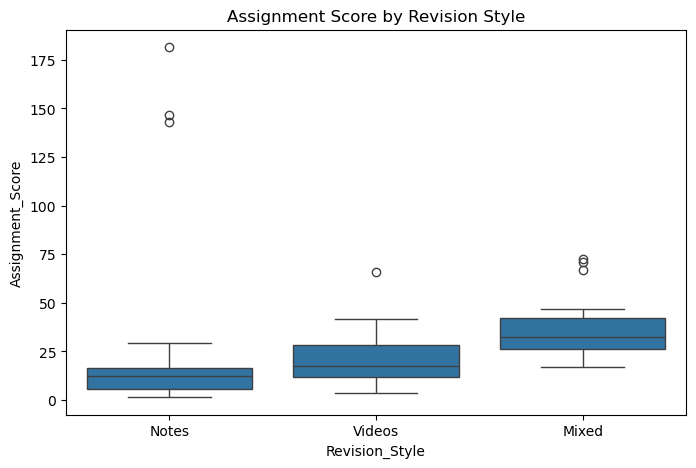

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_kw, x='Revision_Style', y='Assignment_Score')
plt.title('Assignment Score by Revision Style')
plt.show()

## 23. Run Kruskal–Wallis Test

- H0: all groups have similar distributions / median ranks
- H1: at least one group differs

In [17]:
kw_result = stats.kruskal(
    df_kw[df_kw['Revision_Style'] == 'Notes']['Assignment_Score'],
    df_kw[df_kw['Revision_Style'] == 'Videos']['Assignment_Score'],
    df_kw[df_kw['Revision_Style'] == 'Mixed']['Assignment_Score']
)
print(kw_result)

KruskalResult(statistic=np.float64(24.56993684210525), pvalue=np.float64(4.620681185212118e-06))


### Compare against one-way ANOVA

Kruskal-Wallis is described as the non-parametric alternative to one-way ANOVA. Run the
ANOVA too, and see what it misses.

In [18]:
# Standalone on purpose: this cell reloads and re-imports so it runs whether or
# not you have filled in the TODO cells above.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
df_kw = pd.read_csv('../../00-data/assignment_score.csv', index_col=0)
groups = [df_kw[df_kw['Revision_Style'] == g]['Assignment_Score']
          for g in ['Notes', 'Videos', 'Mixed']]

f_stat, f_p = stats.f_oneway(*groups)
h_stat, h_p = stats.kruskal(*groups)

print(f"One-way ANOVA     F = {f_stat:7.3f}   p = {f_p:.4f}   {'SIGNIFICANT' if f_p < 0.05 else 'not significant'}")
print(f"Kruskal-Wallis    H = {h_stat:7.3f}   p = {h_p:.6f}   {'SIGNIFICANT' if h_p < 0.05 else 'not significant'}")
print()
print(df_kw.groupby('Revision_Style')['Assignment_Score']
           .agg(['mean', 'median', 'std']).round(1))
print("""
Look at the Notes row: the mean is far above the median and the standard
deviation dwarfs the other two groups. A few students in that group scored
enormously higher than the rest.

Those few rows pull the Notes MEAN up towards the Mixed mean and inflate the
within-group variance that ANOVA divides by. F gets small, p gets large, and
ANOVA concludes there is nothing to find.

Kruskal-Wallis compares rank positions, which those extreme values barely
affect, and detects the difference clearly.
""")

One-way ANOVA     F =   1.604   p = 0.2081   not significant
Kruskal-Wallis    H =  24.570   p = 0.000005   SIGNIFICANT

                mean  median   std
Revision_Style                    
Mixed           36.6    32.5  15.2
Notes           28.5    12.5  49.4
Videos          20.9    17.5  14.0

Look at the Notes row: the mean is far above the median and the standard
deviation dwarfs the other two groups. A few students in that group scored
enormously higher than the rest.

Those few rows pull the Notes MEAN up towards the Mixed mean and inflate the
within-group variance that ANOVA divides by. F gets small, p gets large, and
ANOVA concludes there is nothing to find.

Kruskal-Wallis compares rank positions, which those extreme values barely
affect, and detects the difference clearly.



## 24. Why Post Hoc?

Kruskal–Wallis only tells us at least one group differs — not which ones. Use **Dunn's test** with Bonferroni adjustment.

## 25. Dunn Post Hoc Test

In [19]:
posthoc_kw = sp.posthoc_dunn(
    df_kw,
    val_col='Assignment_Score',
    group_col='Revision_Style',
    p_adjust='bonferroni'
)
posthoc_kw

,Mixed,Notes,Videos
Mixed,1.000000,0.000004,0.002118
Notes,0.000004,1.000000,0.449156
Videos,0.002118,0.449156,1.000000


## 26. Interpretation Template

> A Kruskal–Wallis test was conducted to compare assignment scores across three revision styles (Notes, Videos, Mixed). Because the synthetic data uses progressively higher gamma `shape` parameters, the omnibus test is expected to be significant. Dunn's post hoc with Bonferroni adjustment then identifies which specific pairs differ — typically Notes vs Mixed shows the strongest separation, while Notes vs Videos may not reach significance.

# Part D — Friedman Test

## 27. Scenario
Same students performance across 3 learning platforms (repeated, non-normal).

## 28. Load the Repeated Measures Dataset

In [20]:
df_friedman = pd.read_csv('../../00-data/platform_performance.csv')
df_friedman.head()

,Student_ID,Platform_A,Platform_B,Platform_C
0,1,7.71,10.09,11.63
1,2,3.33,4.59,9.06
2,3,22.12,22.18,31.35
3,4,14.45,17.95,22.55
4,5,9.66,10.42,16.40


## 29. Convert to Long Format

In [21]:
df_friedman_long = df_friedman.melt(
    id_vars='Student_ID',
    value_vars=['Platform_A', 'Platform_B', 'Platform_C'],
    var_name='Platform',
    value_name='Performance_Score'
)
df_friedman_long.head()

,Student_ID,Platform,Performance_Score
0,1,Platform_A,7.71
1,2,Platform_A,3.33
2,3,Platform_A,22.12
3,4,Platform_A,14.45
4,5,Platform_A,9.66


## 30. Run Friedman Test

- H0: the repeated conditions are similar
- H1: at least one condition differs

In [22]:
friedman_result = stats.friedmanchisquare(
    df_friedman['Platform_A'],
    df_friedman['Platform_B'],
    df_friedman['Platform_C']
)
print(friedman_result)

FriedmanchisquareResult(statistic=np.float64(29.100000000000023), pvalue=np.float64(4.797503368127275e-07))


### What the Bonferroni correction costs you

The pairwise Wilcoxon tests below are corrected for multiple comparisons. Watch what the
correction does to one of the three pairs: **its raw p-value is significant and its
corrected p-value is not.**

This is the correction working as designed. Running three tests at α = 0.05 gives you
roughly a 14% chance of at least one false positive, so Bonferroni multiplies each
p-value by the number of comparisons. The price of controlling false positives is that
genuine but marginal effects stop clearing the bar.

In [23]:
# Standalone on purpose: this cell reloads and re-imports so it runs whether or
# not you have filled in the TODO cells above.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
df_friedman = pd.read_csv('../../00-data/platform_performance.csv')
pairs = [('Platform_A', 'Platform_B'), ('Platform_A', 'Platform_C'), ('Platform_B', 'Platform_C')]

rows = []
for a, b in pairs:
    res = stats.wilcoxon(df_friedman[a], df_friedman[b])
    rows.append({'pair': f"{a[-1]} vs {b[-1]}",
                 'p_raw': round(res.pvalue, 4),
                 'p_bonferroni': round(min(res.pvalue * len(pairs), 1.0), 4),
                 'raw?': 'sig' if res.pvalue < 0.05 else '-',
                 'bonf?': 'sig' if min(res.pvalue * len(pairs), 1.0) < 0.05 else '-'})

print(pd.DataFrame(rows).to_string(index=False))
print("""
One pair changes verdict between the two columns. Reporting only its raw
p-value would be overstating what this experiment can support.
""")

  pair  p_raw  p_bonferroni raw? bonf?
A vs B 0.0240        0.0719  sig     -
A vs C 0.0000        0.0000  sig   sig
B vs C 0.0001        0.0003  sig   sig

One pair changes verdict between the two columns. Reporting only its raw
p-value would be overstating what this experiment can support.



## 31. Post Hoc After Friedman

Pairwise Wilcoxon signed-rank tests with Bonferroni adjustment.

In [24]:
pairs = [
    ('Platform_A', 'Platform_B'),
    ('Platform_A', 'Platform_C'),
    ('Platform_B', 'Platform_C')
]

results = []
for a, b in pairs:
    stat, p = stats.wilcoxon(df_friedman[a], df_friedman[b])
    results.append([a, b, stat, p])

posthoc_friedman = pd.DataFrame(results, columns=['Group_1', 'Group_2', 'Statistic', 'p_raw'])
posthoc_friedman['p_bonf'] = np.minimum(posthoc_friedman['p_raw'] * 3, 1.0)
posthoc_friedman

,Group_1,Group_2,Statistic,p_raw,p_bonf
0,Platform_A,Platform_B,45.0,0.023951,0.071852
1,Platform_A,Platform_C,0.0,0.000002,0.000006
2,Platform_B,Platform_C,1.0,0.000103,0.000310


## 32. Interpretation Template

> A Friedman test was conducted to compare performance scores across three learning platforms. Because the synthetic data adds progressively larger upward shifts (B > A, C > A), expect the omnibus test to be significant. Pairwise Wilcoxon signed-rank tests with Bonferroni adjustment then identify which pairs differ — typically all three pairs reach significance, with the largest effect for Platform_A vs Platform_C.

# Part E — Spearman Correlation

## 33. Scenario
Relationship between study time (integer hours) and exam rank score.

## 34. Load the Dataset

In [25]:
df_spear = pd.read_csv('../../00-data/study_exam_rank.csv')
df_spear.head()

,Study_Time,Exam_Rank
0,6.7,24
1,9.1,16
2,5.5,25
3,21.2,8
4,11.1,17


## 35. Run Spearman Correlation

- positive coefficient → as one increases, the other tends to increase
- p-value < 0.05 → statistically significant association

In [26]:
spearman_result = stats.spearmanr(df_spear['Study_Time'], df_spear['Exam_Rank'])
print(spearman_result)

SignificanceResult(statistic=np.float64(-0.9502721128092426), pvalue=np.float64(7.54038954313344e-21))


### Compare against Pearson

Spearman is recommended here because the data is ordinal and the relationship is not a
straight line. Run Pearson on the same two columns and compare.

Spearman rho =  -0.950   p = 7.54e-21
Pearson  r   =  -0.756   p = 1.71e-08
gap in absolute strength: 0.194


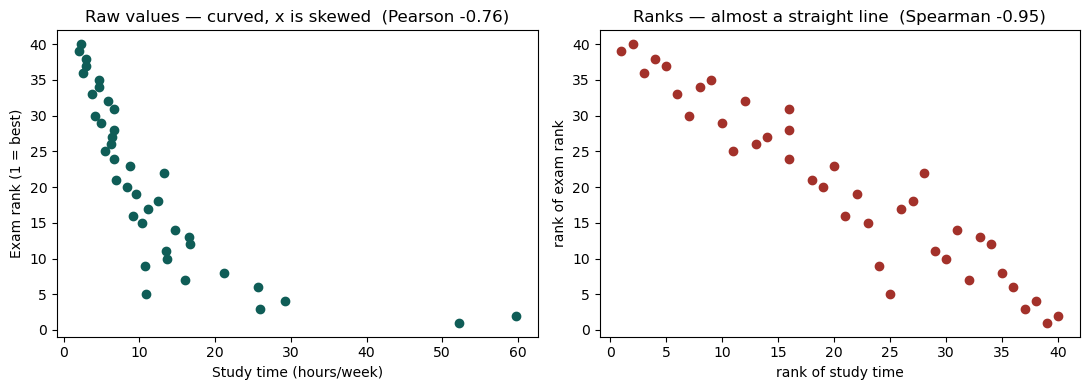


Both plots describe the same 40 students.

Pearson measures how STRAIGHT the left panel is, and it is not straight: study
time is heavily right skewed while rank is bounded between 1 and 40, so the
top students are separated by huge differences in hours but only one place in
the ranking. Pearson is punished for that curvature.

Spearman replaces both variables with their ranks, which is the right panel,
and measures how straight THAT is. The relationship is consistently increasing,
so Spearman scores it correctly.

If you had screened this feature with Pearson you would have judged it much
weaker than it is.



In [27]:
# Standalone on purpose: this cell reloads and re-imports so it runs whether or
# not you have filled in the TODO cells above.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
df_spear = pd.read_csv('../../00-data/study_exam_rank.csv')
sp_r, sp_p = stats.spearmanr(df_spear['Study_Time'], df_spear['Exam_Rank'])
pe_r, pe_p = stats.pearsonr(df_spear['Study_Time'], df_spear['Exam_Rank'])

print(f"Spearman rho = {sp_r:7.3f}   p = {sp_p:.2e}")
print(f"Pearson  r   = {pe_r:7.3f}   p = {pe_p:.2e}")
print(f"gap in absolute strength: {abs(sp_r) - abs(pe_r):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(df_spear['Study_Time'], df_spear['Exam_Rank'], color='#0F5D57')
ax[0].set(xlabel='Study time (hours/week)', ylabel='Exam rank (1 = best)',
          title=f'Raw values — curved, x is skewed  (Pearson {pe_r:.2f})')
ax[1].scatter(df_spear['Study_Time'].rank(), df_spear['Exam_Rank'].rank(), color='#A3312A')
ax[1].set(xlabel='rank of study time', ylabel='rank of exam rank',
          title=f'Ranks — almost a straight line  (Spearman {sp_r:.2f})')
plt.tight_layout(); plt.show()

print("""
Both plots describe the same 40 students.

Pearson measures how STRAIGHT the left panel is, and it is not straight: study
time is heavily right skewed while rank is bounded between 1 and 40, so the
top students are separated by huge differences in hours but only one place in
the ranking. Pearson is punished for that curvature.

Spearman replaces both variables with their ranks, which is the right panel,
and measures how straight THAT is. The relationship is consistently increasing,
so Spearman scores it correctly.

If you had screened this feature with Pearson you would have judged it much
weaker than it is.
""")

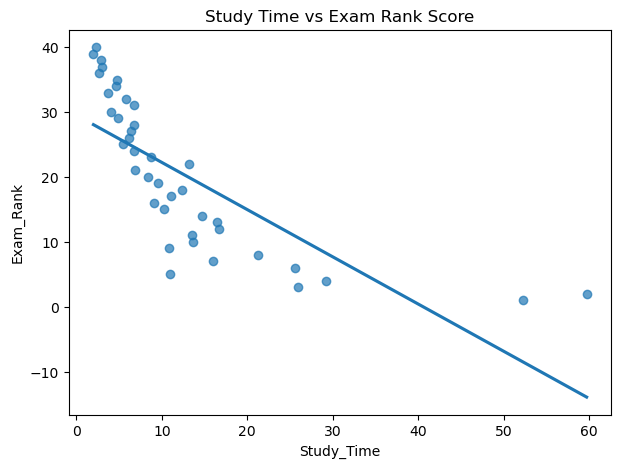

In [28]:
# Optional scatter plot for the lecture
plt.figure(figsize=(7, 5))
sns.regplot(data=df_spear, x='Study_Time', y='Exam_Rank', ci=None,
            scatter_kws={'alpha': 0.7})
plt.title('Study Time vs Exam Rank Score')
plt.show()

## 36. Quick Decision Rule Chart

| Question | Groups | Independent or Paired | Test |
|---|---|---|---|
| Compare 2 groups | 2 | Independent | Mann–Whitney U |
| Compare 2 measurements | 2 | Paired | Wilcoxon signed-rank |
| Compare 3+ groups | 3+ | Independent | Kruskal–Wallis |
| Compare 3+ measurements | 3+ | Paired / repeated | Friedman |
| Ranked / non-normal correlation | — | — | Spearman |

## 37. Important Teaching Notes

- Non-parametric ≠ better — it is **more suitable** when assumptions are violated.
- These tests usually operate on **ranks**, making them robust to skew, outliers, and ordinal data.
- Always **inspect distributions first** before defaulting to non-parametric methods.

## 38. Full Workflow Summary Cell

In [29]:
# 1. Mann-Whitney U
print('Mann-Whitney U:')
print(stats.mannwhitneyu(online, physical, alternative='two-sided'))

# 2. Wilcoxon signed-rank
print('\nWilcoxon signed-rank:')
print(stats.wilcoxon(df_wil['Confidence_Before'], df_wil['Confidence_After']))

# 3. Kruskal-Wallis
print('\nKruskal-Wallis:')
print(stats.kruskal(
    df_kw[df_kw['Revision_Style'] == 'Notes']['Assignment_Score'],
    df_kw[df_kw['Revision_Style'] == 'Videos']['Assignment_Score'],
    df_kw[df_kw['Revision_Style'] == 'Mixed']['Assignment_Score']
))

# 4. Friedman
print('\nFriedman:')
print(stats.friedmanchisquare(
    df_friedman['Platform_A'],
    df_friedman['Platform_B'],
    df_friedman['Platform_C']
))

# 5. Spearman correlation
print('\nSpearman correlation:')
print(stats.spearmanr(df_spear['Study_Time'], df_spear['Exam_Rank']))

Mann-Whitney U:
MannwhitneyuResult(statistic=np.float64(112.0), pvalue=np.float64(6.045949421012785e-07))

Wilcoxon signed-rank:
WilcoxonResult(statistic=np.float64(72.0), pvalue=np.float64(0.01487055165581049))

Kruskal-Wallis:
KruskalResult(statistic=np.float64(24.56993684210525), pvalue=np.float64(4.620681185212118e-06))

Friedman:
FriedmanchisquareResult(statistic=np.float64(29.100000000000023), pvalue=np.float64(4.797503368127275e-07))

Spearman correlation:
SignificanceResult(statistic=np.float64(-0.9502721128092426), pvalue=np.float64(7.54038954313344e-21))


## Student Exercise

All three datasets are provided. For each task, **run the parametric test as well** and
report whether the two tests agree.

### Task 1 — `../data/branch_satisfaction.csv`
Customer satisfaction ratings (1-10, ordinal) across three branches: Northgate,
Riverside, Eastfield. Use **Kruskal-Wallis**, then **Dunn's post hoc** to find which
branches differ. Note that a mean rating is not a meaningful number on an ordinal scale.

### Task 2 — `../data/training_before_after.csv`
Staff performance scores before and after a training programme, same 30 people measured
twice. Use **Wilcoxon signed-rank**. Check normality on the *differences* first, and
compare against a paired t-test.

### Task 3 — `../data/app_users.csv`
Session length in minutes for Free and Premium app users. Heavily right skewed, as
session data always is. Use **Mann-Whitney U**, and compare the group means against the
group medians before you interpret anything.

### For every task
1. Justify why the non-parametric test is the appropriate choice.
2. State H₀ and H₁.
3. Run the test and report the statistic and p-value.
4. Run the parametric equivalent and say whether it agrees.
5. Run the post hoc test where one applies.
6. Write a one-paragraph conclusion in plain language.

In [30]:
# Task 1 — Customer satisfaction across 3 branches → Kruskal-Wallis + Dunn
# ex_df = pd.read_csv('branch_satisfaction.csv')
# print(ex_df.groupby('Branch')['Satisfaction'].agg(['mean','median','std','count']))
# sns.boxplot(data=ex_df, x='Branch', y='Satisfaction'); plt.show()
# print(stats.kruskal(*[ex_df[ex_df['Branch']==b]['Satisfaction'] for b in ex_df['Branch'].unique()]))
# print(sp.posthoc_dunn(ex_df, val_col='Satisfaction', group_col='Branch', p_adjust='bonferroni'))

# Task 2 — Before/after training performance → Wilcoxon signed-rank
# ex_df = pd.read_csv('../../00-data/training_before_after.csv')
# print(stats.wilcoxon(ex_df['Before'], ex_df['After']))

# Task 3 — 2 independent groups of app users → Mann-Whitney U
# ex_df = pd.read_csv('../../00-data/app_users.csv')
# g1 = ex_df[ex_df['Group']=='A']['Metric']
# g2 = ex_df[ex_df['Group']=='B']['Metric']
# print(stats.mannwhitneyu(g1, g2, alternative='two-sided'))

## 40. Reflection Questions — Model Answers

**1. Why do non-parametric tests often use ranks instead of means?**
> Ranks are robust to skewness and outliers. By converting raw values into their relative ordering, the test is less influenced by extreme values and does not require a specific distributional shape. This makes ranks a natural fit for ordinal data and small or skewed samples.

**2. When should Mann–Whitney U be used instead of an independent t-test?**
> When the data violates t-test assumptions: clearly non-normal (especially with small samples), strong outliers, or ordinal measurement. Mann–Whitney U compares the distributions / median ranks of two independent groups without assuming normality.

**3. Why do we need Dunn's test after Kruskal–Wallis?**
> Kruskal–Wallis is an omnibus test — it tells us *that* at least one group differs but not *which* groups. Dunn's test runs all pairwise comparisons on rank sums while controlling the family-wise error rate (e.g. via Bonferroni), pinpointing the specific differences.

**4. What is the difference between Wilcoxon and Friedman?**
> Wilcoxon signed-rank compares **two related** measurements (e.g. before vs after on the same subjects). Friedman extends this to **three or more related** measurements (e.g. the same subjects under multiple conditions). Both rely on within-subject differences, but Friedman handles the multi-condition case.

**5. Why is Spearman correlation preferred for ordinal or non-normal data?**
> Pearson assumes a linear relationship between two normally distributed continuous variables. Spearman uses the **ranks** of the data, so it captures any **monotonic** relationship and works on ordinal data, ranked data, or non-normal continuous data without distorting the result.

## 41. Summary

Students learned to: identify when assumptions for parametric tests fail, choose the appropriate non-parametric alternative from a decision chart, run the test in Python (`scipy.stats` or `pingouin`), perform post hoc analysis with `scikit_posthocs` or pairwise Wilcoxon, and interpret p-values in plain language.